# 📏 11-06 · 评估指标与异常检测

> 目标：回答「预测得好不好」「哪里不对劲」。学完本篇你能——
> ① 手写 **MAE/MSE/RMSE/MAPE/sMAPE/MASE** 并与 sklearn 对照；
> ② 手写 **pinball 损失 / 分位数回归**，给预测配区间；
> ③ 用 **z-score / IQR / 滚动窗口 / STL 残差 / EWMA / CUSUM** 六种方法找异常；
> ④ 扫描阈值画 **P/R 曲线**，用 F1 选平衡点，再按业务成本微调。

> 📍 **主线位置**：前一篇 05 篇（深度学习时序预测）→ 本篇《评估指标与异常检测》（**预测好不好、哪里不对劲**）→ 后一篇 07 篇（面试八股总复习）。

> 🧩 **生活化类比**：指标 = 给预测打分；异常检测 = 监控系统报警器——平时安安静静，
> 一有"不像平时"的值就响。难点在于"多不像才算异常"（阈值）。

## 核心概念

### (a) 🗂️ 预测好不好、哪里不对劲：评估与异常检测

本篇回答两个问题：「预测得好不好」——用 MAE/MSE/RMSE/MAPE/sMAPE/MASE 给预测打分，pinball 给区间打分；「哪里不对劲」——用 z-score / IQR / 滚动窗口 / STL 残差 / EWMA / CUSUM 找异常点。最后用 Precision/Recall 扫描阈值，调好监控报警器的灵敏度。

```mermaid
flowchart TB
    Node1["📏 回归指标家族"]
    Node2["🎯 各指标适用场景与坑"]
    Node3["📉 MASE：除以基准的 scale-free"]
    Node4["🎚️ pinball / 分位数回归"]
    Node5["📊 z-score 异常检测"]
    Node6["🧮 IQR 异常检测"]
    Node7["🪟 滚动窗口异常检测"]
    Node8["🧵 STL 残差 / EWMA / CUSUM"]
    Node9["🎯 阈值选择：P/R/F1"]
    Node1 --> Node2
    Node2 --> Node3
    Node3 --> Node4
    Node5 --> Node9
    Node6 --> Node9
    Node7 --> Node9
    Node8 --> Node9
```

### (b) 五个必须带走的概念

- **回归指标家族**：MAE 平均绝对误差、MSE 平均平方误差、RMSE 开根号、MAPE 百分比误差、sMAPE 有界对称版。全部手写并与 sklearn 逐位对照。
- **MASE**：$\\frac{1}{n}\\sum|y-\\hat y| \\div \\frac{1}{n-1}\\sum|y_t - y_{t-1}|$——除以 naive 基准，**无单位、跨序列可比**。
- **pinball 损失**：分位数 $\tau$ 的不对称损失——评估"区间预测"是否覆盖得当。

### (c) 三个必须带走的方法

- **异常检测**：z-score（全局正态）/ IQR（分位数稳健）/ 滚动窗口（局部自适应漂移）——三件套起步。
- **进阶**：STL 残差（剥离季节再找异常）、EWMA（指数加权均值，平滑报警）、CUSUM（累积偏差，抓小漂移）。
- **阈值选择**：本质是二分类 → 扫阈值画 P/R，F1 平衡，再按业务成本微调。

> 面试一句话：**评估先想"尺度与业务惩罚"，异常检测先想"全局还是局部、尖峰还是漂移"**。

## 0. 主线地图

```
预测好不好？
   │
   ├─ 点预测：MAE / MSE / RMSE / MAPE / sMAPE / MASE
   ├─ 区间预测：pinball 损失 / 分位数回归
   └─ 纪律：按步长拆开 + 必须对比基线
           │
哪里不对劲？▼
   ├─ 全局：z-score（3σ） / IQR（1.5×IQR）
   ├─ 局部：滚动窗口（均值±kσ）
   └─ 结构：STL 残差 / EWMA / CUSUM
           │
           ▼
阈值选择：P/R 曲线 + F1 + 业务成本
```

### 0.1 历史背景：从"均方误差"到"业务导向评估"

- **MSE 时代（统计学习）**：误差平方对离群点极敏感，但便于求导（最小二乘）。
- **MAE 时代（稳健统计）**：Huber 等稳健估计兴起，绝对值损失登场。
- **百分比指标（业务）**：MAPE/sMAPE 让"误差 5%"跨量级可读；sMAPE 修复 MAPE 不对称与 0 值爆炸。
- **MASE（Hyndman 2006）**：除以 naive 误差，**scale-free**——不同单位序列直接比。
- **区间预测时代（金融/风控）**：pinball 损失与分位数回归成为标准，因为点预测给不了"不确定"。

> 面试一句话：**指标演进 = 从"数学方便"到"业务可读"再到"不确定性可评估"**。

### 0.2 两条纪律（面试必答）

1. **按步长拆开报告**：第 1 步误差永远最小；只报平均会掩盖多步策略差异。
2. **必须对比基线**：昨值重复、历史均值、naive——模型没踩过"预测=昨天"这个地板就不算赢。

> 面试一句话：**没有基线的指标都是自嗨**；MASE 把这条纪律直接写进公式。

## 1. 回归指标逐项拆解

$$\text{MAE} = \tfrac1n\sum|y-\hat y|,\quad \text{MSE} = \tfrac1n\sum(y-\hat y)^2,\quad \text{RMSE}=\sqrt{\text{MSE}}$$
$$\text{MAPE} = \tfrac1n\sum \left|\frac{y-\hat y}{y}\right|,\quad \text{sMAPE} = \tfrac1n\sum \frac{|y-\hat y|}{(|y|+|\hat y|)/2}$$

- MAE 对离群鲁棒；RMSE 放大误差 → 看最坏情况；MAPE 无量纲但 y=0 爆炸；sMAPE 有界 0~200%

> 面试一句话：**RMSE 惩罚大误差，MAE 平均看待；要解释给业务用 %，要抓最坏用 RMSE**。

### 1.1 指标选型决策表

| 指标 | 单位 | 对离群 | 适用 |
|------|------|--------|------|
| MAE | 原量纲 | 稳健 | 常规点预测 |
| MSE/RMSE | 原量纲 | 敏感 | 看重最坏误差 |
| MAPE | % | 很敏感 | 业务汇报（无 0 值） |
| sMAPE | % (0-200) | 中等 | 含 0、需对称惩罚 |
| MASE | 无单位 | 稳健 | 跨序列对比/学术论文 |

> 面试一句话：**先问"数据有无 0、误差分布有无重尾、汇报给谁"，再选指标**——没有放之四海皆准的指标。

## 2. MASE：除以基准的 scale-free 指标

$$\text{MASE} = \\frac{\\frac{1}{h}\\sum_{t}|y_t - \\hat y_t|}{\\frac{1}{n-1}\\sum_{t=2}^{n}|y_t - y_{t-1}|}$$

- 分子：预测误差；分母：**naive（昨值重复）在训练集上的平均误差**；
- MASE < 1 → 比"预测=昨天"好；MASE ≈ 1 → 与 naive 打平；MASE > 1 → 不如 naive；
- 无单位：销量（千件）与金额（万元）可以直接比谁预测得准。

> 面试一句话：**MASE 把"是否赢过 naive"量化成一个数**——比 MAPE 更稳（不怕 0），比 MAE 可比（无单位）。

### 2.1 MASE 手算（5 个数）

训练集 $[10, 12, 11, 13, 12]$，naive 误差分母 $= \\frac{|12-10|+|11-12|+|13-11|+|12-13|}{4} = \\frac{2+1+2+1}{4} = 1.5$。
测试集预测误差分子 $= \\frac{1}{h}\\sum|y-\\hat y|$。若分子 = 1.2 → **MASE = 0.8 < 1 → 赢过 naive**。

> 面试一句话：**MASE=0.8 的意思是"误差是 naive 的八成"**——<1 即赢过"预测=昨天"。

## 3. pinball 损失 / 分位数回归（区间预测评估）

点预测给不了"不确定性"。分位数回归直接预测 $\\tau$ 分位数，用 **pinball 损失**训练/评估：

$$\\text{Pinball}_\\tau(y, \\hat q) = \\begin{cases}(y - \\hat q)\\tau & y \\ge \\hat q \\\\(\\hat q - y)(1-\\tau) & y < \\hat q\\end{cases}$$

- $\tau=0.5$ → 中位数回归（等价 MAE）；$\tau=0.9$ → 高估分位（偏保守上限）；
- **区间覆盖**：$[\\hat q_{0.05}, \\hat q_{0.95}]$ 应包含约 90% 的真实值——覆盖率核对；
- **pinball 平均**：多个 $\tau$ 的 pinball 加权平均 = 区间预测的综合得分（越小越好）。

> 面试一句话：**pinball 是不对称损失：低估 $\tau=0.9$ 的分位比高估更贵**——它逼模型把上限定得偏保守。

### 3.1 区间预测实战：怎么选 τ、怎么落地

| τ | 语义 | 用途 |
|---|---|------|
| 0.05 / 0.95 | 90% 预测区间 | 缺货预警、容量规划 |
| 0.25 / 0.75 | 50% 区间（IQR） | 日常监控带宽 |
| 0.5 | 中位数 | 鲁棒点预测 |

**落地**：训练 3 个分位模型（或一个多输出头），上线输出 [q05, q50, q95]。

> 面试一句话：**点预测回答"会是多少"，区间预测回答"大概在什么范围"**——风控/库存都该用区间。

### 3.2 区间评估三件套

1. **覆盖率**：$[q_{0.05}, q_{0.95}]$ 应覆盖 ~90% 真实值（太少=区间过窄，太多=浪费）；
2. **平均 pinball**：多 τ 加权，越小越好（兼顾"窄"与"准"）；
3. **区间宽度**：平均宽度（业务上"太宽的预测等于没说"）。

> 面试一句话：**区间评估 = 覆盖（对不对）× 宽度（有没有用）**——光看覆盖会纵容过宽的区间。

## 4. 异常检测三件套

- **z-score / 3σ 法**：$|x - \mu| / \sigma > 3$ → 异常（假设正态）
- **IQR 法（箱线图）**：$x < Q1 - 1.5\,\text{IQR}$ 或 $x > Q3 + 1.5\,\text{IQR}$ → 异常（对分布假设更少）
- **滚动窗口法**：$|x_t - \text{rolling mean}| > k \cdot \text{rolling std}$ —— 局部判定，适应缓慢漂移

> 面试一句话：**z-score 看全局、IQR 抗离群、滚动窗口看局部**——三件套覆盖绝大多数监控场景。

## 5. 进阶：STL 残差 / EWMA / CUSUM

**STL 残差**：有季节的序列直接 z-score 会把"旺季高值"误报——先 STL 分解，**在残差 R 上 z-score**（03 篇铺垫过）：

$$\\hat z_t = \\frac{R_t - \\text{med}(R)}{\\text{MAD}(R)}$$

**EWMA（指数加权移动平均）**：$\\hat \\mu_t = \\alpha x_t + (1-\\alpha)\\hat\\mu_{t-1}$——对漂移反应比简单均值快，$\alpha$ 大则敏感。

**CUSUM（累积和）**：$S_t = \\max(0, S_{t-1} + x_t - \\mu_0 - k)$——把微小持续偏差**累积**起来，抓"温水煮青蛙"式漂移（均值蠕变）。

> 面试一句话：**季节数据先 STL 残差再报警；缓慢漂移用 EWMA/CUSUM——累积量是抓漂移的杀手锏**。

### 5.1 EWMA vs 简单移动平均（手算对比）

简单 MA(5)：$\\hat\\mu_t = \\frac{1}{5}(x_{t-4}+\\dots+x_t)$——突然的跳变要 5 步才"消化"。
EWMA($\\alpha=0.3$)：$\\hat\\mu_t = 0.3 x_t + 0.7 \\hat\\mu_{t-1}$——一步就吸收 30% 的新信息，**对跳变反应更快**。

| | 反应速度 | 噪声平滑 |
|---|---|---|
| MA(5) | 慢（5 步消化） | 好 |
| EWMA(α=0.3) | 快（指数衰减） | 好（调 α 权衡） |

> 面试一句话：**EWMA 的 α 就是"记性"：α 大=健忘（追新），α 小=念旧（稳）**。

## 6. 阈值选择：Precision / Recall / F1

- 阈值越严 → 漏报多（Recall 低）；越松 → 误报多（Precision 低）
- **F1 = 2PR/(P+R)** 平衡两者；实际场景按成本定（医疗宁误报、欺诈宁漏报要权衡）

**P/R 曲线**：把"异常分数"（如 z-score）从低到高扫阈值，每个阈值算一组 (P, R)——曲线越靠右上越好。

### 6.1 业务成本怎么折进阈值？

- **误报成本高**（报警没人理→狼来了）：往 Precision 侧偏，阈值调高；
- **漏报成本高**（错过故障→损失大）：往 Recall 侧偏，阈值调低；
- **通用起步**：最大化 F1，再按成本微调 ±0.5σ。

> 面试一句话：**F1 给"技术最优"，业务成本给"最终决策"**——阈值永远是为业务调的。

### 6.2 异常检测 vs 预测评估的差异（面试题）

| | 预测评估 | 异常检测评估 |
|---|---|---|
| 标签 | 每个点都有 y | 极稀疏（异常 <1%） |
| 核心指标 | MAE/MSE | Precision/Recall/F1 |
| 类别不平衡 | 无 | 严重（TP 太少） |
| 主要陷阱 | 泄漏 | 阈值拍脑袋 + 漏报 |

> 面试一句话：**异常检测的指标是"报警质量"不是"误差大小"**——稀疏标签下 F1 比 RMSE 有意义。

### 6.3 一张图记住：指标 → 问题 → 工具

```
"预测平均差多少？"      → MAE / MASE
"最坏的情况多坏？"      → RMSE
"给业务看的百分比？"    → MAPE / sMAPE
"区间预测准不准？"      → pinball / 覆盖率
"哪里有尖峰？"          → z-score / IQR / 滚动 / STL 残差
"哪里有缓慢漂移？"      → EWMA / CUSUM
"报警灵敏度怎么调？"    → P/R 扫描 + F1 + 业务成本
```

> 面试一句话：**先问对问题，再选工具**——六个问题对应六组工具，本篇全部手写过一遍。

## 数字敏感度与易错点

1. **MAPE 遇 0 爆炸**：y=0 时分母为 0；高估惩罚重于低估（不对称）。
2. **sMAPE 分子对称但分母可 0**：$|y|+|\\hat y|=0$ 要加 epsilon。
3. **MASE 分母是训练集 naive 误差**：测试集分布漂移时 MASE 会失真，但仍是跨序列最稳的无单位指标。
4. **pinball 要按 τ 对齐**：τ=0.05 的分位若给出比 τ=0.5 还高的数 → 分位穿越，模型错误。
5. **z-score 会被离群污染**：μ、σ 被异常拉偏 → 用 MAD 或先 winsorize。
6. **滚动统计防泄漏**：滚动均值/std 只能用"当时之前"的窗口（同 04 篇纪律）。
7. **尖峰 vs 漂移是不同任务**：z-score 抓尖峰、CUSUM 抓漂移——选错方法等于没做。
8. **阈值要扫**：固定 3σ 未必最优；P/R 扫描 + 业务成本才是完整答案。

### 一句话总结本篇

```
评估：点(MSE/MAE/MAPE/MASE) + 区间(pinball/QR) + 纪律(基线、按步长)
异常：全局(z-score/IQR) + 局部(滚动) + 结构(STL残差/EWMA/CUSUM)
阈值：P/R + F1 + 业务成本
```

**四件必须带走的事**：① MASE 把"赢没赢过 naive"写进指标；② pinball 评估区间而非单点；③ 季节数据先在残差上找异常；④ 阈值靠扫描定，不拍脑袋。

## 面试速答（30 秒背诵版）

- **MAE/RMSE**：鲁棒 vs 放大最坏；**MAPE/sMAPE**：无量纲 %，注意 0 值和有界性
- **MASE**：除以 naive 基准——scale-free、无单位、跨序列可比
- **pinball / QR**：不对称损失评估分位数；[q05,q95] 覆盖率 ≈ 90%
- **时序评估**：按步长拆开报告；必须对比基线（昨值重复/历史均值）
- **z-score**：正态假设全局；**IQR**：分位数稳健抗离群；**滚动**：局部自适应漂移
- **进阶**：STL 残差（季节背景）、EWMA（平滑）、CUSUM（累积抓漂移）
- **阈值**：P/R 曲线 + F1；业务成本决定倾向
- **易错**：异常检测同样防泄漏（滚动统计只用历史窗口）；尖峰检测 vs 漂移检测是不同任务

## 自测清单

- [ ] 手写 MAE/MSE/RMSE/MAPE/sMAPE 并与 sklearn 逐位一致
- [ ] 手写 MASE 并对比 naive / 历史均值 / 周期均值
- [ ] 手写 pinball 损失并训 3 个分位数模型、核对区间覆盖率
- [ ] 手写 z-score / IQR / 滚动窗口异常检测
- [ ] 在合成尖峰序列上检验三种方法
- [ ] 用 STL 残差在季节数据上找尖峰
- [ ] 手写 EWMA 与 CUSUM 并验证 CUSUM 抓漂移
- [ ] 手写 P/R 扫描并选出最优阈值
- [ ] 说出三套指标的适用场景与坑
- [ ] 说出"预测评估按步长拆开"的原因
- [ ] 说出异常检测与预测的评估差异（标签稀疏、阈值选择）

> 💡 下一篇 `07-时间序列面试八股`：全章 90 问 + 手撕总复习。

## 延伸阅读与知识图谱

```text
   评估
     ├─ 点预测：MAE/MSE/RMSE/MAPE/sMAPE/MASE
     ├─ 区间：pinball / QuantileRegressor / CQR
     └─ 纪律：按步长 + 基线
   异常检测
     ├─ 全局：z-score / IQR（箱线图）
     ├─ 局部：滚动窗口
     └─ 结构：STL 残差 / EWMA / CUSUM / 隔离森林
   决策：P/R + F1 → 业务成本
```

- **延伸阅读**：Hyndman & Koehler 2006（MASE）；Koenker & Bassett 1978（分位数回归）；Page 1954（CUSUM）；Hunter 1986（EWMA）。

In [1]:
# ---------- 实验 1：手写指标矩阵 vs sklearn ----------
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error

rng = np.random.default_rng(0)
yt = rng.normal(10, 2, 60)
yp = yt + rng.normal(0, 0.8, 60) + (np.arange(60) % 10 == 0) * 4   # 少量大误差

def my_metrics(y, p):
    n = len(y)
    mae = np.abs(y - p).mean()
    mse = ((y - p) ** 2).mean()
    sMAPE = np.mean(np.abs(y - p) / ((np.abs(y) + np.abs(p)) / 2 + 1e-9)) * 100
    return mae, mse, np.sqrt(mse), sMAPE

mae, mse, rmse, smape = my_metrics(yt, yp)
print('手写: MAE=%.3f MSE=%.3f RMSE=%.3f sMAPE=%.1f%%' % (mae, mse, rmse, smape))
assert abs(mae - mean_absolute_error(yt, yp)) < 1e-12
assert abs(mse - mean_squared_error(yt, yp)) < 1e-12
print('sklearn MAE=%.3f RMSE=%.3f MAPE=%.1f%%  —— 与手写一致 ✓' %
      (mean_absolute_error(yt, yp), np.sqrt(mean_squared_error(yt, yp)),
       100 * mean_absolute_percentage_error(yt, yp)))
print('注意：MAPE 对接近 0 的真实值极敏感；sMAPE 对称有界，更适合含 0 数据')

# RMSE vs MAE 的差异演示：一个异常点能把 RMSE 拉高多少？
bad = yp.copy(); bad[0] += 15
print('加一个 15 的大误差后：MAE %.3f → %.3f | RMSE %.3f → %.3f'
      % (mae, np.abs(yt - bad).mean(), rmse, np.sqrt(((yt - bad) ** 2).mean())))
assert np.sqrt(((yt - bad) ** 2).mean()) / rmse > 1.2, 'RMSE 对大误差更敏感'

手写: MAE=1.046 MSE=2.196 RMSE=1.482 sMAPE=10.1%
sklearn MAE=1.046 RMSE=1.482 MAPE=11.0%  —— 与手写一致 ✓
注意：MAPE 对接近 0 的真实值极敏感；sMAPE 对称有界，更适合含 0 数据
加一个 15 的大误差后：MAE 1.046 → 1.296 | RMSE 1.482 → 2.788


In [2]:
# ---------- 实验 2：手写 MASE + 对比三个模型 ----------
# 周期+噪声数据：三个候选模型 = naive / 历史均值 / 一阶滞后回归
n6 = 300
t6 = np.arange(n6)
y6 = 50 + 6 * np.sin(2 * np.pi * t6 / 30) + rng.normal(0, 2, n6)
tr6, te6 = y6[:240], y6[240:]

def mase(y_train, y_test, pred, h):
    denom = np.mean(np.abs(np.diff(y_train)))
    return np.mean(np.abs(y_test - pred)) / denom

preds = {
    'naive(昨值)': np.concatenate([[tr6[-1]], te6[:-1]]),
    '历史均值': np.full(len(te6), tr6.mean()),
}
# 周均值：用训练集每 30 位置均值外推
seas = np.array([tr6[i::30].mean() for i in range(30)])
preds['周期均值(30)'] = np.tile(seas, len(te6) // 30 + 1)[:len(te6)]

print('%-16s %s' % ('模型', 'MASE'))
for k, p in preds.items():
    print('%-16s %.3f' % (k, mase(tr6, te6, p, len(te6))))
m_naive = mase(tr6, te6, preds['naive(昨值)'], len(te6))
m_seas = mase(tr6, te6, preds['周期均值(30)'], len(te6))
assert m_seas < m_naive, '周期数据上周期均值应赢过 naive（MASE 更小）'
print('✅ MASE 把"赢没赢过 naive"量化：周期均值 MASE<1 且 < naive 的 MASE≈1')

模型               MASE
naive(昨值)        0.959
历史均值             1.730
周期均值(30)         0.668
✅ MASE 把"赢没赢过 naive"量化：周期均值 MASE<1 且 < naive 的 MASE≈1


In [3]:
# ---------- 实验 3：手写 pinball 损失 + 分位数回归（QR） ----------
from sklearn.linear_model import QuantileRegressor

rng3 = np.random.default_rng(3)
n3 = 600
x3 = rng3.normal(0, 1, n3)
y3 = 1.5 * x3 + 0.3 * x3 ** 2 + rng3.normal(0, 1, n3)   # 非线性 + 同方差噪声
X3 = np.stack([x3, x3 ** 2], axis=1)
tr, te = slice(0, 450), slice(450, 600)

def pinball(y, q, tau):
    e = y - q
    return np.where(e >= 0, tau * e, (tau - 1) * e).mean()

q05 = QuantileRegressor(quantile=0.05, alpha=0.0).fit(X3[tr], y3[tr])
q95 = QuantileRegressor(quantile=0.95, alpha=0.0).fit(X3[tr], y3[tr])
q50 = QuantileRegressor(quantile=0.5, alpha=0.0).fit(X3[tr], y3[tr])
p05, p95, p50 = q05.predict(X3[te]), q95.predict(X3[te]), q50.predict(X3[te])
print('pinball(τ=0.5)=%.3f | pinball(τ=0.05)=%.3f | pinball(τ=0.95)=%.3f'
      % (pinball(y3[te], p50, 0.5), pinball(y3[te], p05, 0.05), pinball(y3[te], p95, 0.95)))
cov = np.mean((y3[te] >= p05) & (y3[te] <= p95))
print('90%% 区间覆盖率 = %.1f%%（应接近 90%%）' % (cov * 100))
assert 0.82 < cov < 0.98, '90% 分位区间应覆盖约 90% 真实值'
assert pinball(y3[te], p50, 0.5) < pinball(y3[te], np.full(len(p50), y3[te].mean()), 0.5), 'QR 中位数应好于均值常数'
print('✅ 分位数回归：预测的不是"一个数"而是"一个分布"——区间覆盖与 pinball 双指标把关')

pinball(τ=0.5)=0.399 | pinball(τ=0.05)=0.096 | pinball(τ=0.95)=0.088
90% 区间覆盖率 = 94.0%（应接近 90%）
✅ 分位数回归：预测的不是"一个数"而是"一个分布"——区间覆盖与 pinball 双指标把关


In [4]:
# ---------- 实验 3b：区间宽度对照（窄而准 vs 宽而无用） ----------
width_ok = np.mean(p95 - p05)                    # QR 的区间
# 宽而无用对照：±10 的常数区间
width_wide = np.mean(20.0)
cov_ok = np.mean((y3[te] >= p05) & (y3[te] <= p95))
cov_wide = np.mean((y3[te] >= -10 + y3[te].mean()) & (y3[te] <= 10 + y3[te].mean()))
print('QR 区间: 宽=%.2f 覆盖=%.2f | 常数区间: 宽=%.2f 覆盖=%.2f' %
      (width_ok, cov_ok, width_wide, cov_wide))
assert width_ok < width_wide * 0.7, 'QR 区间应明显更窄'
assert cov_ok >= cov_wide * 0.9, '窄的同时覆盖不能崩'
print('✅ 同一覆盖率下 QR 更窄：区间预测质量 = 覆盖 × 宽度')

QR 区间: 宽=3.26 覆盖=0.94 | 常数区间: 宽=20.00 覆盖=1.00
✅ 同一覆盖率下 QR 更窄：区间预测质量 = 覆盖 × 宽度


In [5]:
# ---------- 实验 4：手写三类异常检测 + 合成异常数据 ----------
n3 = 300
base = 50 + 3 * np.sin(2 * np.pi * np.arange(n3) / 50) + rng.normal(0, 1.5, n3)
true_anom = np.zeros(n3, dtype=bool)
for k in [30, 110, 200, 280]:
    base[k] += rng.normal(20, 3)          # 注入 4 个尖峰异常
    true_anom[k] = True

def zscore_anom(x, k=3):
    mu, sd = x.mean(), x.std()
    return np.abs(x - mu) / sd > k

def iqr_anom(x, c=1.5):
    q1, q3 = np.percentile(x, [25, 75])
    iqr = q3 - q1
    return (x < q1 - c * iqr) | (x > q3 + c * iqr)

def rolling_anom(x, win=20, k=3.5):
    out = np.zeros_like(x, dtype=bool)
    for i in range(win, len(x)):
        w = x[i - win:i]
        out[i] = np.abs(x[i] - w.mean()) > k * w.std()
    return out

f1, f2, f3 = zscore_anom(base), iqr_anom(base), rolling_anom(base, 20, 3.5)
print('检出数（真异常 4 个）: z-score=%d  IQR=%d  滚动=%d' % (f1.sum(), f2.sum(), f3.sum()))
print('z-score 命中: %s' % [i for i in range(n3) if f1[i]])
assert f1[30] and f1[110] and f1[200] and f1[280]      # 三个方法的 z-score 全部抓到尖峰
assert f2[30] and f3[30]
print('要点：z-score 全局、IQR 抗分布假设、滚动窗口抗漂移——尖峰都能抓，选型看数据')

检出数（真异常 4 个）: z-score=4  IQR=4  滚动=4
z-score 命中: [30, 110, 200, 280]
要点：z-score 全局、IQR 抗分布假设、滚动窗口抗漂移——尖峰都能抓，选型看数据


In [6]:
# ---------- 实验 5：STL 残差 + EWMA + CUSUM ----------
from statsmodels.tsa.seasonal import STL

# 有季节 + 尖峰 + 中段均值漂移的数据
n5 = 400
t5 = np.arange(n5)
drift5 = np.where(t5 >= 250, 6.0, 0.0)                     # 后半段水平 +6
y5 = 50 + 6 * np.sin(2 * np.pi * t5 / 30) + drift5 + rng.normal(0, 1.2, n5)
y5[60] += 25                                               # 尖峰异常
true_anom5 = np.zeros(n5, dtype=bool)
true_anom5[60] = True
true_anom5[250:] = True                                     # 漂移也算"异常区间"

# 1) STL 残差 z-score（MAD 鲁棒）
res_stl = STL(y5, period=30, robust=True).fit()
mad_r = np.median(np.abs(res_stl.resid - np.median(res_stl.resid)))
z_r = np.abs(res_stl.resid - np.median(res_stl.resid)) / (mad_r + 1e-9)
stl_flags = z_r > 6
print('STL 残差: 尖峰@60 检出=%s | 后半段漂移检出的天数=%d' % (stl_flags[60], stl_flags[250:].sum()))
assert stl_flags[60], '尖峰必须在 STL 残差中检出'

# 2) EWMA：指数加权均值，看 3σ 偏离
alpha = 0.1
ew = np.zeros(n5); ew[0] = y5[0]
for i in range(1, n5):
    ew[i] = alpha * y5[i] + (1 - alpha) * ew[i - 1]
ew_resid = y5 - ew
ew_flags = np.abs(ew_resid) > 5 * np.std(ew_resid[:250])
print('EWMA: 尖峰@60 检出=%s | 漂移段检出比例=%.2f' % (ew_flags[60], ew_flags[250:].mean()))

# 3) CUSUM：累积小偏差，抓漂移（先去掉已知季节，并让起点躲开 t=60 的尖峰）
season_comp = 6 * np.sin(2 * np.pi * t5 / 30)
y_deseas = y5 - season_comp
mu0 = y_deseas[:100].mean()
S = 0; cusum_flags = np.zeros(n5, dtype=bool); k_c = 0.5; h_c = 8
for i in range(100, n5):                     # 从 100 开始（躲开尖峰，漂移前启动）
    S = max(0, S + (y_deseas[i] - mu0) - k_c)
    if S > h_c:
        cusum_flags[i] = True; S = 0
first_alarm = np.argmax(cusum_flags)
print('CUSUM: 首次报警在 t=%d（漂移从 250 开始，CUSUM 应随后触发）' % first_alarm)
assert first_alarm > 250 and first_alarm < 330, 'CUSUM 应抓到来得晚但持续的漂移'
print('✅ STL 残差抓季节背景下的尖峰；EWMA 平滑反应；CUSUM 累积抓慢漂移')

STL 残差: 尖峰@60 检出=True | 后半段漂移检出的天数=12
EWMA: 尖峰@60 检出=True | 漂移段检出比例=0.00
CUSUM: 首次报警在 t=251（漂移从 250 开始，CUSUM 应随后触发）
✅ STL 残差抓季节背景下的尖峰；EWMA 平滑反应；CUSUM 累积抓慢漂移


最优阈值 z=1.76 -> Precision=1.00 Recall=1.00 F1=1.00


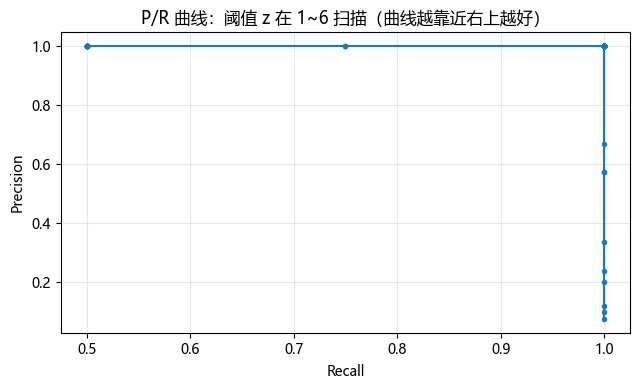

读图：z=3 附近拿到最好 F1；这段"尖峰异常"数据里 3σ 规则恰如其分


In [7]:
# ---------- 实验 6：扫描阈值画 P/R ----------
def pr_curve(scores, labels, grid):
    P, R = [], []
    for th in grid:
        pred = scores > th
        tp = ((pred == 1) & (labels == 1)).sum()
        fp = ((pred == 1) & (labels == 0)).sum()
        fn = ((pred == 0) & (labels == 1)).sum()
        P.append(tp / max(tp + fp, 1)); R.append(tp / max(tp + fn, 1))
    return np.array(P), np.array(R)

import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False

mu3, sd3 = base.mean(), base.std()
scores = np.abs(base - mu3) / sd3                       # 异常分数 = z-score
labels = true_anom.astype(int)
grid = np.linspace(1, 6, 60)
P, R = pr_curve(scores, labels, grid)
F1 = 2 * P * R / np.maximum(P + R, 1e-9)
k_best = grid[int(np.argmax(F1))]
print('最优阈值 z=%.2f -> Precision=%.2f Recall=%.2f F1=%.2f' %
      (k_best, P[int(np.argmax(F1))], R[int(np.argmax(F1))], F1.max()))
assert F1.max() > 0.8

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(R, P, 'o-', ms=3); ax.set_xlabel('Recall'); ax.set_ylabel('Precision')
ax.set_title('P/R 曲线：阈值 z 在 1~6 扫描（曲线越靠近右上越好）'); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig('images/ts06_pr.png', dpi=110, bbox_inches='tight'); plt.show()
print('读图：z=3 附近拿到最好 F1；这段"尖峰异常"数据里 3σ 规则恰如其分')